In [2]:
import numpy as np
import matplotlib.pyplot as plt
import utils
import scipy
import sklearn

In [3]:
datasets = open("3d.txt").readlines()
datasets = [d.strip() for d in datasets]
datasets = [d for d in datasets if d != "RF00375"]
null_sets = [d + "_null1" for d in datasets]
ss_files = [f"data/{d}/ss.txt" for d in datasets]
    

In [10]:
def calc_p_values(data, null_data):

    scores = np.load(f"data/{data}/reg0.5_mireg0.01_scoreoptdiff_corrAPC.npz")['corrected_scores']
    null_scores = np.load(f"data/{null_data}/reg0.5_mireg0.01_scoreoptdiff_corrAPC.npz")['corrected_scores']    

    fit = scipy.stats.gamma.fit(null_scores)
    
    print(fit)

    p_vals = scipy.stats.gamma.logsf(scores, *fit)

    return p_vals

def calc_p_values_no_null(data):
    
    scores = np.load(f"data/{data}/reg0.5_mireg0.01_scoreoptdiff_corrAPC.npz")['corrected_scores']
    L = utils.reverse_triangle_number(len(scores)) + 1

    fit_scores = np.partition(scores, -L//2)[:-L//2]
    
    fit = scipy.stats.exponnorm.fit(fit_scores)
    
    print(fit)
    
    p_vals = scipy.stats.exponnorm.logsf(scores, *fit)
    return p_vals

In [11]:
def pairs_from_secondary(input_string: str) -> list[tuple[int, int]]:
    """
        Will give a list of pairs of indices that are paired in the secondary structure.
        (i,j): i < j is garanteed
    """
    open_par = ['(', '[', '{', '<', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J']
    close_par = [')', ']', '}', '>', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j']

    stacks = {}  # Contains tuple with (is_open, stack)

    for open, close in zip(open_par, close_par):
        stacks[open] = (True, [])
        stacks[close] = (False, stacks[open][1])  # Points to the same stack

    result = []  # List to store pairs of matching indices

    for index, char in enumerate(input_string):
        if char in stacks:
            is_open, stack = stacks[char]
            if is_open:
                stack.append(index)
            else:
                open_index = stack.pop()
                result.append((open_index, index))

    assert (all([not bool(stack) for (_, stack) in stacks.values()]))

    return result

In [12]:
def collect(method):
    all_mask = []
    all_scores = []
    if method == "phylo_score_null":
        p_values = [calc_p_values(d, n) for d, n in zip(datasets, null_sets)]
    elif method == "phylo_score":
        p_values = [calc_p_values_no_null(d) for d in datasets]
    elif method == "phylo_score_pure_score":
        scores = [np.load(f"data/{d}/reg0.5_mireg0.01_scoreoptdiff_corrAPC.npz")['corrected_scores'] for d in datasets]
        p_values = [-s for s in scores]
    elif method == "rscape":
        score_files = [f"data/{d}/rscape_GTp.npz" for d in datasets]
        p_values = [np.load(f)['p_values'] for f in score_files]
    for p_val, ss in zip(p_values, ss_files):
        ss = open(ss, 'r').read().strip()
        true_pairs = pairs_from_secondary(ss)
        all_pairs = np.triu_indices(len(ss), k = 1)

        mask = [p in true_pairs for p in zip(all_pairs[0], all_pairs[1])]
        
        all_mask.extend(mask)
        all_scores.extend(-p_val)
    return np.array(all_mask), np.array(all_scores)

In [13]:
from sklearn.metrics import precision_recall_curve, average_precision_score

def plot_pr_curves(mask, scores : list, labels):
    plt.figure(figsize=(10, 10))
    for s, l in zip(scores, labels):
        precision, recall, _ = precision_recall_curve(mask, s)
        ap = average_precision_score(mask, s)
        plt.plot(recall, precision, label=f"{l} (AP={ap:.2f})")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision-Recall Curves")
    plt.legend()
    plt.grid()
    plt.show()

In [15]:
mask, rscape_scores = collect("rscape")
_, pure_scores = collect("phylo_score_pure_score")
_, phylo_score_scores = collect("phylo_score")
_, phylo_score_null_scores = collect("phylo_score_null")

(np.float64(1.0684943849389108), np.float64(-4.023800440100622), np.float64(2.7058936636618838))
(np.float64(1.1168656866598914), np.float64(-7.329521990208944), np.float64(3.6227873225938154))
(np.float64(1.907346464144092), np.float64(-3.9733825090232795), np.float64(1.6855567786029828))
(np.float64(1.2027344483373992), np.float64(-3.5734016492002336), np.float64(2.405880847577114))
(np.float64(2.4938209714695003), np.float64(-4.396574367368279), np.float64(1.5335318291905846))
(np.float64(1.4415916955148944), np.float64(-2.64963718274923), np.float64(1.7107055231948909))
(np.float64(1.9639458008267083), np.float64(-3.047947345627991), np.float64(1.4822405175640991))
(np.float64(1.477085579736399), np.float64(-3.6798145453757116), np.float64(2.337875629270295))
(np.float64(1.0625048941156763), np.float64(-2.9266532081051353), np.float64(2.3163526573574957))
(np.float64(1.7659990376389718), np.float64(-3.413490048116927), np.float64(1.759913953339232))
(np.float64(1.8504722997797902),

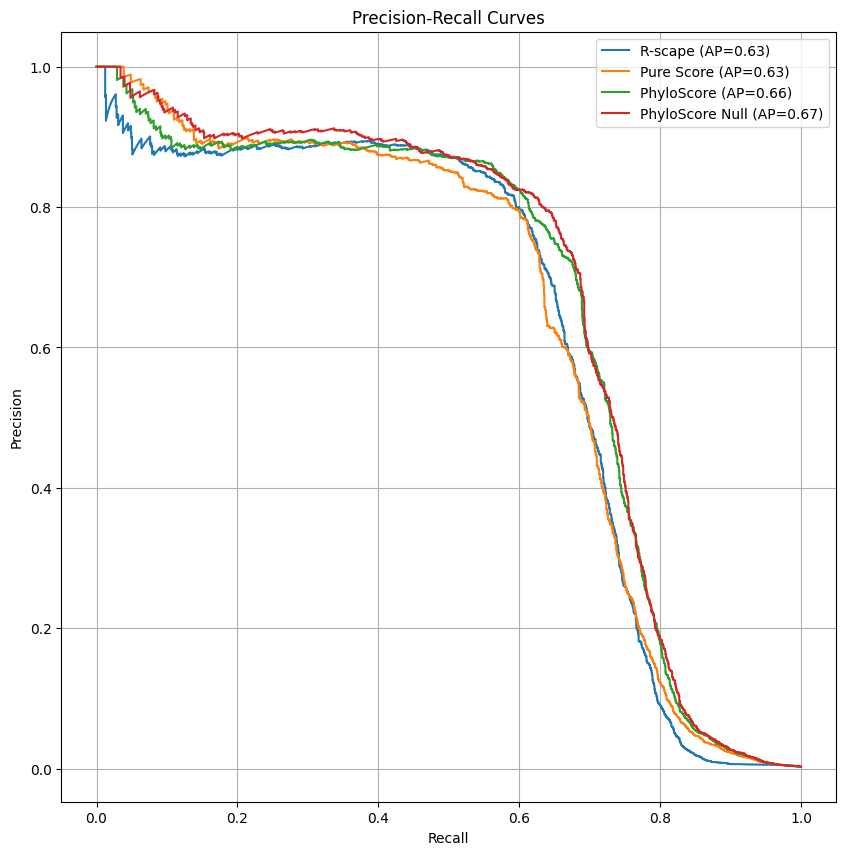

In [16]:
plot_pr_curves(mask, [rscape_scores, pure_scores, phylo_score_scores, phylo_score_null_scores], labels=["R-scape", "Pure Score", "PhyloScore", "PhyloScore Null"])

In [ ]:
scores2.max()

np.float64(inf)